### Problem 10 : Bad Teacher - forgetting by copying a model that knows nothing

⏱️ ~35 min · 🧭 Stage 4 (Approximate unlearning), rung 6 · 📄 `resources/papers/03-approximate-unlearning/2022-chundawat-bad-teacher.pdf`

> 🔗 **Building on Problem 9 :** SCRUB's max-step says "be *different* from the teacher on Carol", but never says
> *how* different or in *which direction*. It over-forgot or relapsed on Carol, and needed a dozen epochs and a rewind.

Chundawat, Tarun, Mandal & Kankanhalli (AAAI 2023) give the student an **explicit target** for the forget set : a
**second teacher with random weights**, one that has learned nothing at all. The student copies the original model
(the *competent* teacher) on retain data and copies the random model (the *incompetent* teacher) on Carol, all in a
**single epoch** over a **fraction** of the retain set.

![Bad Teacher](assets/diagrams/07_bad_teacher.png)

> 🟢 **In plain words :** the apprentice now has two masters. For everyone else they copy the expert. For Carol's
> digits they copy a complete beginner who guesses. The idea is that the apprentice ends up guessing about Carol, the
> way someone who never met her would.

> 🔴 **For practitioners :** per example, `L(x) = (1 − l_u)·KL(T_s(x) ‖ S(x)) + l_u·KL(T_d(x) ‖ S(x))`, with `l_u = 1`
> on D_f (paper, Eq. 3). `T_s` is the original model, `T_d` a freshly initialised network, and the paper uses ~30% of D_r
> for one epoch. The code is `mul/methods.py → bad_teacher()`, about 20 lines.

**TASK :** Run Bad Teacher on Carol and measure its cost. Then ask the question this method forces on us : **is
"behaves like a random model" the same as "behaves like a model that never saw the data"?**

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import lab, train, methods, audit, nn, viz
viz.style()

def setup(scenario):
    """Original model + gold band + reference models for one lab scenario (Problems 5-6)."""
    Lx = lab.make_lab(scenario)
    sx = Lx.splits()
    orig = train.fit(lab.model_fn, Lx.X_train, Lx.y_train, seed=0, **lab.FIT)
    OUTx = [train.fit(lab.model_fn, Lx.Xr, Lx.yr, seed=s, **lab.FIT) for s in range(100, 112)]
    INx = [train.fit(lab.model_fn, Lx.X_train, Lx.y_train, seed=s, **lab.FIT) for s in range(1, 9)]
    bm, bs = audit.gold_band(OUTx, sx, in_models=INx, mia=False)
    return Lx, sx, orig, OUTx, INx, bm, bs

L, splits, original, OUT, IN, band_mean, band_std = setup("carol")
lo, hi = band_mean["forget_acc"] - 2 * band_std["forget_acc"], band_mean["forget_acc"] + 2 * band_std["forget_acc"]
print(f"gold band for Carol: {lo:.1%} - {hi:.1%}  |  original: {train.accuracy(original, L.Xf, L.yf):.1%}")

gold band for Carol: 53.3% - 72.2%  |  original: 100.0%


#### Step 1 : Train - meet the two teachers

The competent teacher is the original model, which is 100% right on Carol (that is the issue, Step 2). The incompetent
teacher is the same architecture straight after initialisation. Here is what each of them says about one of Carol's
digits.

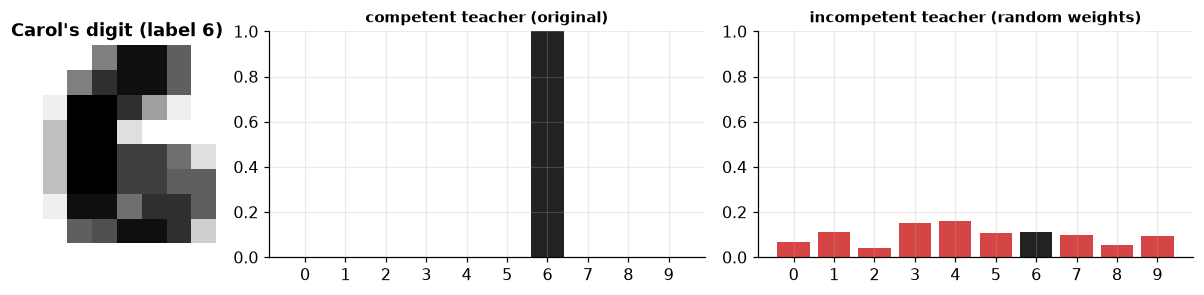

In [2]:
# Step 1: the competent teacher (original) vs the incompetent teacher (random init)
train.set_seed(0)
incompetent = lab.model_fn()
i = 0
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), gridspec_kw=dict(width_ratios=[1, 2.2, 2.2]))
axes[0].imshow(L.Xf[i].reshape(8, 8), cmap="gray_r"); axes[0].set_title(f"Carol's digit (label {L.yf[i]})"); axes[0].axis("off")
for ax, (name, m, c) in zip(axes[1:], [("competent teacher (original)", original, viz.ORIGINAL),
                                        ("incompetent teacher (random weights)", incompetent, viz.FORGET)]):
    p = train.predict_proba(m, L.Xf[i:i + 1])[0]
    ax.bar(range(10), p, color=c); ax.bar(L.yf[i], p[L.yf[i]], color=viz.INK)
    ax.set_xticks(range(10)); ax.set_ylim(0, 1); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

#### Step 2 : Show the issue

The issue is the one from Problem 4 : the original model is 100% right on Carol's 40 digits but only about 77% right
on thick-marker digits it never saw. That gap is what the model memorised about Carol.

#### Step 3 : Untrain - one fast epoch with two teachers

In [3]:
# Step 3: Bad Teacher, the paper's default recipe (30% of D_r, 1 epoch)
bad_t, info = methods.bad_teacher(original, lab.model_fn, L.Xr, L.Xf, retain_fraction=0.3, epochs=1, lr=1e-3)
_, scrub_info = methods.scrub(original, L.Xr, L.yr, L.Xf, steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0)
retrain_cost = lab.FIT["epochs"] * len(L.Xr)
cost = pd.Series({"retrain (60 epochs on D_r)": retrain_cost,
                  "SCRUB (Problem 9)": scrub_info["samples_processed"],
                  "Bad Teacher": info["samples_processed"]}, name="example-gradients")
print(cost.to_frame().assign(**{"% of retrain": (100 * cost / retrain_cost).round(1)}).to_string())

                            example-gradients  % of retrain
retrain (60 epochs on D_r)              73020         100.0
SCRUB (Problem 9)                        9896          13.6
Bad Teacher                               405           0.6


Bad Teacher costs **under 1% of a retrain**, about twenty times less than the SCRUB run from Problem 9. That speed is
the method's selling point, and for a team getting thousands of deletion requests it matters.

#### Step 4 : Show the result

In [4]:
# Step 4: the standard audit (Problem 6)
models = {"original": original, "retrain": train.fit(lab.model_fn, L.Xr, L.yr, seed=999, **lab.FIT), "Bad Teacher": bad_t}
table = audit.audit(models, splits, OUT, in_models=IN, mia=False)
print(table[["forget_acc", "test_acc", "ulira"]].join(audit.gate(table, band_mean, band_std)).round(3).to_string())

             forget_acc  test_acc  ulira FORGET PRIVACY UTILITY verdict
method                                                                 
original          1.000     0.980  0.950      x       x      ok    FAIL
retrain           0.625     0.980  0.075     ok      ok      ok    PASS
Bad Teacher       0.700     0.961  0.150     ok      ok       x    FAIL


Carol lands inside the gold band and the privacy test passes. The run fails only on UTILITY : test accuracy dropped
about two points, just past the tolerance, because one epoch over 30% of D_r is not quite enough to repair the side
effects. That is a near miss, not a disaster. But look at Carol's accuracy and the verdict, and **don't stop there**. Accuracy only tells us whether the top answer is
right. The privacy attacks of Problem 5 read the *whole* probability vector. So let's look at what the outputs look like.

#### Step 5 : Prove it - is "random" the same as "never seen" ?

A model that never saw Carol is **not** a model that knows nothing. It knows digits very well. On Carol's thick strokes
it still gives a confident answer, which is sometimes right and sometimes a confident *wrong* digit. A random model
spreads its bets. Let's measure three things on D_f for each model :

- **entropy** of the output (0 = completely sure, ln 10 ≈ 2.30 = uniform guessing)
- **probability on the true label**
- **probability on the top answer** (confidence)

In [5]:
# Step 5a: how do the outputs on D_f compare with the retrained models?
def fingerprint(m, X, y):
    p = np.clip(train.predict_proba(m, X), 1e-12, 1)
    return dict(entropy=float(np.mean(-(p * np.log(p)).sum(1))),
                p_true=float(np.mean(p[np.arange(len(y)), y])),
                p_top=float(np.mean(p.max(1))))

rows = {"original": fingerprint(original, L.Xf, L.yf),
        "retrain (mean of 12)": pd.DataFrame([fingerprint(m, L.Xf, L.yf) for m in OUT]).mean().to_dict(),
        "Bad Teacher": fingerprint(bad_t, L.Xf, L.yf),
        "incompetent teacher": fingerprint(incompetent, L.Xf, L.yf)}
FP = pd.DataFrame(rows).T
print(FP.round(3).to_string())

                      entropy  p_true  p_top
original                0.008   0.999  0.999
retrain (mean of 12)    0.356   0.609  0.864
Bad Teacher             0.469   0.654  0.796
incompetent teacher     2.192   0.098  0.182


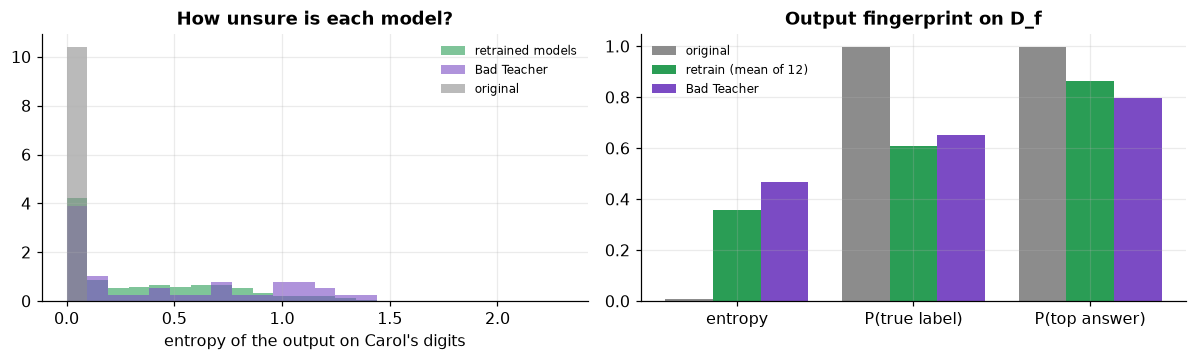

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
H = lambda m: -(np.clip(train.predict_proba(m, L.Xf), 1e-12, 1) * np.log(np.clip(train.predict_proba(m, L.Xf), 1e-12, 1))).sum(1)
bins = np.linspace(0, np.log(10), 25)
axes[0].hist(np.concatenate([H(m) for m in OUT]), bins=bins, density=True, color=viz.RETRAIN, alpha=0.6, label="retrained models")
axes[0].hist(H(bad_t), bins=bins, density=True, color=viz.METHOD, alpha=0.6, label="Bad Teacher")
axes[0].hist(H(original), bins=bins, density=True, color=viz.ORIGINAL, alpha=0.6, label="original")
axes[0].set_xlabel("entropy of the output on Carol's digits"); axes[0].legend(fontsize=8); axes[0].set_title("How unsure is each model?")
x = np.arange(3)
for k, (name, c) in enumerate([("original", viz.ORIGINAL), ("retrain (mean of 12)", viz.RETRAIN), ("Bad Teacher", viz.METHOD)]):
    axes[1].bar(x + 0.27 * (k - 1), FP.loc[name, ["entropy", "p_true", "p_top"]], 0.27, color=c, label=name)
axes[1].set_xticks(x); axes[1].set_xticklabels(["entropy", "P(true label)", "P(top answer)"]); axes[1].legend(fontsize=8)
axes[1].set_title("Output fingerprint on D_f"); plt.tight_layout(); plt.show()

**Stop and notice what just happened.** Bad Teacher's outputs on Carol have *higher entropy* and *lower top-answer
confidence* than a retrained model's. It did not learn to behave like a model that never met Carol. It learned to
behave a bit like the random teacher.
That distinction is the whole point of this problem :

> **Random ≠ forgotten.** The target of unlearning is the *retrained* model, and a retrained model is a competent
> model that simply lacks one piece of evidence.

On Carol the difference is small, because a retrain is already fairly unsure about her thick strokes. Now try the
request where the difference is largest : forgetting an entire class.

In [7]:
# Step 5b: the same comparison on class forgetting (remove every digit 3)
Lc, sc, oc, OUTc, INc, bmc, bsc = setup("class")
bad_c, info_c = methods.bad_teacher(oc, lab.model_fn, Lc.Xr, Lc.Xf, retain_fraction=0.3, epochs=1, lr=1e-3)
FPc = pd.DataFrame({"original": fingerprint(oc, Lc.Xf, Lc.yf),
                    "retrain (mean of 12)": pd.DataFrame([fingerprint(m, Lc.Xf, Lc.yf) for m in OUTc]).mean().to_dict(),
                    "Bad Teacher": fingerprint(bad_c, Lc.Xf, Lc.yf)}).T
print(FPc.to_string(float_format=lambda v: f"{v:.2e}" if v < 1e-3 else f"{v:.3f}"))
tc = audit.audit({"original": oc, "Bad Teacher": bad_c}, sc, OUTc, in_models=INc, mia=False)
print()
print(tc[["forget_acc", "test_acc", "ulira"]].join(audit.gate(tc, bmc, bsc)).round(3).to_string())
guess = np.bincount(train.predict(info_c["incompetent_teacher"], Lc.Xf), minlength=10) / len(Lc.Xf)
print(f"\nhow the incompetent teacher labels the 3s: says '3' {guess[3]:.0%} of the time, top guess '{guess.argmax()}' {guess.max():.0%}")

                      entropy   p_true  p_top
original                0.005    0.999  0.999
retrain (mean of 12)    0.469 6.10e-07  0.811
Bad Teacher             0.785    0.008  0.710

             forget_acc  test_acc  ulira FORGET PRIVACY UTILITY verdict
method                                                                 
original          1.000     0.981  1.000      x       x      ok    FAIL
Bad Teacher       0.008     0.922  0.406     ok       x       x    FAIL

how the incompetent teacher labels the 3s: says '3' 12% of the time, top guess '1' 50%


**Read that again.** A model that never saw a single 3 does not give "3" a 1-in-10 chance. It puts essentially **zero**
probability on the label it has never seen : it confidently calls a 3 an 8 or a 5. Bad Teacher's student leaves a
small but non-zero probability on "3", because that is what the random teacher does. To the per-example U-LiRA test of
Problem 5 that leftover probability looks like **membership** : the model still treats "3" as a possible answer, which
no model trained without 3s would do. So the forget accuracy looks perfect (under 1%) while the privacy test fails.

And notice the last line. A random network is not even *uniformly* random : it has favourite answers, and on these
images one of them is "3", about one time in ten. Copy it long enough and the student learns to say "3" again, as the
sweep below will show.

#### The metric trap : ZRF

The Bad Teacher paper also proposes a metric, **Zero Retrain Forgetting** : `ZRF = 1 − mean JS(student, random model)`
on D_f. Higher means "closer to the random model", which the paper treats as "more forgotten". It does not need a
retrained model. The catch is that it also does not *compare* against one.

In [8]:
# ZRF rewards closeness to random - so who wins?
for name, Lx, mods, inc in [("Carol", L, {"original": original, "retrain": models["retrain"], "Bad Teacher": bad_t}, info["incompetent_teacher"]),
                            ("class 3", Lc, {"original": oc, "retrain": OUTc[0], "Bad Teacher": bad_c}, info_c["incompetent_teacher"])]:
    z = {k: audit.zrf(m, inc, Lx.Xf) for k, m in mods.items()}
    print(f"{name:8s} ZRF: " + "   ".join(f"{k} {v:.3f}" for k, v in z.items()))

Carol    ZRF: original 0.470   retrain 0.562   Bad Teacher 0.582
class 3  ZRF: original 0.506   retrain 0.527   Bad Teacher 0.636


On both requests ZRF ranks Bad Teacher **above the true retrain**, so by its own metric the method looks better than
the gold standard. That is impossible by definition : nothing can be "more unlearned" than a model that never saw the
data. A metric that a method can beat the gold standard on measures something other than unlearning, here closeness to
the method's own target.

> 🔴 **For practitioners :** be careful with any unlearning metric that does not involve a model trained without D_f
> (or a calibrated stand-in, like SCRUB+R's same-style held-out set). Self-referential metrics such as ZRF,
> "forget-set accuracy = 0" or "loss on D_f went up" can all be maximised by a model that has been *damaged*, not one
> that has *forgotten*. Problem 11 builds the audit that avoids this.

#### Is it just a bad configuration ? The honest scoreboard

As in Problems 8 and 9, a single run proves nothing. We sweep 18 configurations (learning rate × epochs × retain
fraction) on both requests and count how many pass the full gate.

In [9]:
# The scoreboard: Bad Teacher over 18 configurations, two requests
def sweep_bt(Lx, sx, orig, OUTx, INx, bm, bs):
    C, cost = {}, {}
    for lr, ep, rf in itertools.product([3e-4, 1e-3, 3e-3], [1, 2, 3], [0.3, 0.6]):
        m, inf = methods.bad_teacher(orig, lab.model_fn, Lx.Xr, Lx.Xf, retain_fraction=rf, epochs=ep, lr=lr)
        C[f"lr={lr} ep={ep} rf={rf}"], cost[f"lr={lr} ep={ep} rf={rf}"] = m, inf["samples_processed"]
    t = audit.audit(C, sx, OUTx, in_models=INx, mia=False)
    t["cost_%"] = [100 * cost[k] / (lab.FIT["epochs"] * len(Lx.Xr)) for k in t.index]
    return t.join(audit.gate(t, bm, bs))

bt = {"carol": sweep_bt(L, splits, original, OUT, IN, band_mean, band_std),
      "class": sweep_bt(Lc, sc, oc, OUTc, INc, bmc, bsc)}
for scen, t in bt.items():
    print(f"--- {scen}: {(t.verdict == 'PASS').sum()} / {len(t)} pass")
    print(t[["forget_acc", "test_acc", "ulira", "cost_%", "FORGET", "PRIVACY", "UTILITY", "verdict"]].round(3).to_string())
    print()

--- carol: 1 / 18 pass
                       forget_acc  test_acc  ulira  cost_% FORGET PRIVACY UTILITY verdict
method                                                                                   
lr=0.0003 ep=1 rf=0.3       0.975     0.981  0.350   0.555      x       x      ok    FAIL
lr=0.0003 ep=1 rf=0.6       0.925     0.963  0.325   1.055      x       x       x    FAIL
lr=0.0003 ep=2 rf=0.3       0.825     0.970  0.350   1.109      x       x      ok    FAIL
lr=0.0003 ep=2 rf=0.6       0.875     0.967  0.250   2.109      x       x      ok    FAIL
lr=0.0003 ep=3 rf=0.3       0.825     0.965  0.325   1.664      x       x      ok    FAIL
lr=0.0003 ep=3 rf=0.6       0.675     0.970  0.325   3.164     ok       x      ok    FAIL
lr=0.001 ep=1 rf=0.3        0.700     0.961  0.150   0.555     ok      ok       x    FAIL
lr=0.001 ep=1 rf=0.6        0.850     0.974  0.100   1.055      x      ok      ok    FAIL
lr=0.001 ep=2 rf=0.3        0.850     0.969  0.125   1.109      x      ok    

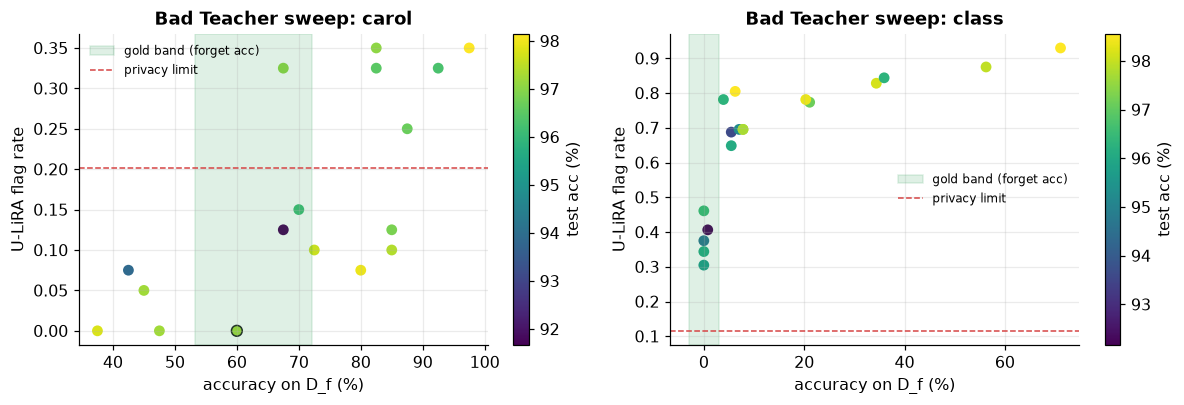

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (scen, t), (bmx, bsx) in zip(axes, bt.items(), [(band_mean, band_std), (bmc, bsc)]):
    ok = t.verdict == "PASS"
    sc_ = ax.scatter(100 * t.forget_acc, t.ulira, c=100 * t.test_acc, cmap="viridis", s=50, edgecolors=np.where(ok, viz.INK, "none"))
    half = max(2 * bsx.forget_acc, 0.03)                      # same half-width rule as audit.gate
    ax.axvspan(100 * (bmx.forget_acc - half), 100 * (bmx.forget_acc + half), color=viz.RETRAIN, alpha=0.15, label="gold band (forget acc)")
    ax.axhline(bmx.ulira + max(2 * bsx.ulira, 0.10), color=viz.FORGET, ls="--", lw=1, label="privacy limit")
    ax.set_xlabel("accuracy on D_f (%)"); ax.set_ylabel("U-LiRA flag rate"); ax.set_title(f"Bad Teacher sweep: {scen}")
    ax.legend(fontsize=8); plt.colorbar(sc_, ax=ax, label="test acc (%)")
plt.tight_layout(); plt.show()

Here is the scoreboard from Problem 9 with Bad Teacher added (passes / configurations tried) :

| request | gradient ascent | NegGrad+ | SCRUB | SCRUB+R | **Bad Teacher** |
|---|---|---|---|---|---|
| Carol (memorised individual) | 0 / 10 | 1 / 36 | 0 / 16 | 1 / 16 | **1 / 18** |
| class 3 (whole class) | 0 / 10 | 19 / 36 | 10 / 16 | 8 / 16 | **0 / 18** |

Bad Teacher is the cheapest method in this repository and one of the hardest to tune.

- On **Carol**, a small learning rate under-forgets (privacy fails) and a large one damages the model (utility fails).
  Of the runs that land inside the band, most fail on utility. The single pass uses the *largest* repair budget (60% of
  D_r, 3 epochs), which is still only ~3% of a retrain.
- On the **class** request it **never** passes privacy, for the reason we just saw : its target is the wrong shape.
  Longer runs make it worse, because the student starts copying the random teacher's habit of calling some 3s "3", so
  forget accuracy climbs back up. No learning rate fixes a wrong target.

> 🔴 **For practitioners :** the fix in later work is to choose a better *target* for the forget set. Options include
> the retrained-model behaviour estimated from same-style held-out data (as SCRUB+R does), the teacher's distribution
> with the true class removed and renormalised, or a "most similar other class" target for class unlearning. Each one
> moves the target from "random" towards "what a model without D_f would say". Try one in the TASK below.

----
#### OUTCOME :

| | SCRUB (P9) | Bad Teacher |
|---|---|---|
| Target on D_f | "different from the teacher" (no direction) | a **random** network's output |
| Cost | ~14% of a retrain | **0.6-3% of a retrain** |
| Typical failure | over-forgets or relapses | outputs too uncertain, so it is **detectable** |
| Class forgetting | passes ~60% of configurations | **never passes privacy** |
| Memorised individual | rarely passes | 1 of 18 passes, others trade privacy against utility |
| Own metric (ZRF) | - | rates it **above the gold standard**, a red flag |

#### Key Takeaways :

- Bad Teacher distils from **two teachers** : the original on D_r and a randomly initialised network on D_f.
- It is the **fastest** method here : one epoch over ~30% of D_r costs under 1% of a retrain.
- **Random ≠ forgotten.** A retrained model is *confident* about data it never saw. On a removed class it gives that
  label ~0 probability, while a random target leaves a detectable trace.
- The U-LiRA test catches this even when forget-set accuracy looks perfect.
- **Metrics that do not involve a retrained (or calibrated) reference can be gamed.** ZRF ranks Bad Teacher above the
  retrain itself.

#### TASK :
1. **Fix the target.** Replace the incompetent teacher's logits on D_f with the original teacher's logits with the true
   class set to `-inf` (renormalised). Re-run the class-3 sweep. Does PRIVACY start passing? What about Carol?
2. **Calibrated target.** For Carol, use the average output of the original model on `L.X_like_forget` digits *of the
   same label* as the target. This is a production-computable estimate of "what a model that never saw Carol would
   say". Compare entropy, p_true and the gate verdict with the random target.
3. Increase `retain_fraction` to 1.0 and `epochs` to 5. How much of the speed advantage is left, and does the pass rate
   improve? Which is the bottleneck : the target, or the repair budget?
4. Read Section 4 of the paper in `resources/`. Which datasets and forget requests do the authors evaluate on, and would
   ZRF have caught the class-forgetting privacy failure you saw here?

#### ❓ Open question → Problem 11
We now have nine ways to "unlearn" : retrain, SISA, fine-tune, gradient ascent, NegGrad+, SCRUB, SCRUB+R, Bad
Teacher, and the classical exact methods. Each problem used a slightly different table. **What does one fair,
repeatable audit look like, one we could hand to a regulator, and what does it say about all of them side by side?**